In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/osm-melbourne-cafe-resto/melbourne_cafes_restaurants_clean.csv



# Task 3: Semantic Search with FAISS  
**Unit Mapping:** BSBDAT501 (3.1–3.5), ICTDAT401 (2.2–3.3), BSBCRT404 (3)

**Objective:** Build a reproducible semantic search workflow over the *Melbourne Cafés & Restaurants* dataset using two approaches:  
1) TF‑IDF (lexical baseline) + FAISS  
2) SBERT MiniLM (semantic embeddings, optional) + FAISS  

**Deliverables:** FAISS indexes, top‑k retrieval results, query‑quality summaries, environment log, and a submission ZIP.


In [2]:
# ==========================================================
# 1. LOAD DATASET 
# ==========================================================
# This cell automatically searches for the cleaned dataset file
# "melbourne_cafes_restaurants_clean.csv" in common Kaggle and
# local paths. You can do any of the following:
#
#  Option A (recommended):
#    Use "Add Data" → "Upload" in the right sidebar of this
#    Kaggle notebook, and upload the file directly.
#    Kaggle will create a folder like:
#       /kaggle/input/<your-uploaded-dataset-name>/
#    The script will automatically detect it.
#
#  Option B:
#    If running locally, place the file in a "Data/" folder.
#
#  Notes:
#    - No manual path editing is required unless you change
#      the file name.
#    - The script will print the path it successfully loaded
#      so you can confirm where it came from.
# ==========================================================

from pathlib import Path
import pandas as pd
import glob
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"


FILENAME = "melbourne_cafes_restaurants_clean.csv"

# Candidate paths (common Kaggle and local)
CANDIDATES = [
    f"/kaggle/input/osm-melbourne-cafe-resto/{FILENAME}",  # my Kaggle dataset slug
    f"/kaggle/working/{FILENAME}",                         # if written during run
    f"./{FILENAME}",                                       # root folder
    f"Data/{FILENAME}", "data/{FILENAME}"                  # local folders
]

DATA_PATH = None

# Try the candidate paths first
for p in CANDIDATES:
    try:
        df = pd.read_csv(p)
        DATA_PATH = p
        break
    except Exception:
        pass

# If not found, search all folders under /kaggle/input (covers uploads)
if DATA_PATH is None and Path("/kaggle/input").exists():
    hits = glob.glob(f"/kaggle/input/**/{FILENAME}", recursive=True)
    if hits:
        DATA_PATH = hits[0]
        df = pd.read_csv(DATA_PATH)

# If still not found, raise a friendly message
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not locate {FILENAME}. "
        "Please confirm the dataset was added via Kaggle's 'Add Data' panel "
        "or placed in the 'Data/' folder."
    )

print("Loaded:", DATA_PATH, "| rows:", len(df))

OUT_DIR = Path("/kaggle/working/Task3_Outputs"); OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Loaded:", DATA_PATH, "| rows:", len(df))


Loaded: /kaggle/input/osm-melbourne-cafe-resto/melbourne_cafes_restaurants_clean.csv | rows: 1896
Loaded: /kaggle/input/osm-melbourne-cafe-resto/melbourne_cafes_restaurants_clean.csv | rows: 1896



### Assemble Search Text per Venue (Preprocessing)

Builds a clean, single text string per venue to feed into embedding models.

- **Columns used (if present):** `name`, `amenity`, `cuisine`, `cuisine_primary`, `addr:suburb`, `internet_access`, `outdoor_seating`.  
- **Cleaning:** Fill missing values with blanks, cast to string, trim whitespace.  
- **Concatenation:** Join key fields into a compact description like:  
  `Name | Cuisine=Italian | Amenity=cafe | Suburb=Fitzroy | Outdoor=yes | WiFi=wlan`.  

**Outputs:**  
- `texts`: per‑venue text Series (input to embeddings).  
- `meta`: original metadata aligned by index (for later joins).  


In [3]:

use_cols = [c for c in ["name","amenity","cuisine","cuisine_primary","addr:suburb","internet_access","outdoor_seating"] if c in df.columns]
clean = df[use_cols].fillna("").astype(str).apply(lambda s: s.str.strip())

def row_to_text(r):
    parts = []
    if "name" in r and r["name"]: parts.append(r["name"])
    if "cuisine_primary" in r and r["cuisine_primary"]: parts.append(f"Cuisine={r['cuisine_primary']}")
    if "amenity" in r and r["amenity"]: parts.append(f"Amenity={r['amenity']}")
    if "addr:suburb" in r and r["addr:suburb"]: parts.append(f"Suburb={r['addr:suburb']}")
    if "outdoor_seating" in r and r["outdoor_seating"]: parts.append(f"Outdoor={r['outdoor_seating']}")
    if "internet_access" in r and r["internet_access"]: parts.append(f"WiFi={r['internet_access']}")
    return " | ".join(parts)

texts = clean.apply(row_to_text, axis=1)
meta = df.reset_index(drop=True)
print("Example text:", texts.iloc[0])


Example text: Books n Bites Cafe | Cuisine=sandwich | Amenity=cafe



###  TF‑IDF Embeddings and FAISS Index (Lexical Baseline)

Converts venue text into TF‑IDF vectors and builds a FAISS index for fast similarity search.

- `min_df=2` drops very rare tokens; `ngram_range=(1,2)` captures short phrases.  
- Vectors are L2‑normalised; **IndexFlatIP** uses inner product which equals **cosine similarity** on normalised vectors.  
- Saves the FAISS index and TF‑IDF feature list for reproducibility.


In [4]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
import numpy as np, pandas as pd, json

# Install FAISS if needed (Kaggle: ensure Internet On in Settings)
try:
    import faiss  # type: ignore
except Exception:
    import sys, subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-input", "faiss-cpu==1.7.4"], check=False)
    import faiss  # type: ignore

vectorizer = TfidfVectorizer(min_df=2, ngram_range=(1,2))
X = vectorizer.fit_transform(texts)                 # sparse (n_samples, n_features)

V = X.astype(np.float32).toarray()
V = normalize(V, norm="l2", axis=1).astype("float32")  # cosine via IP on L2-normalized

index_tfidf = faiss.IndexFlatIP(V.shape[1])
index_tfidf.add(V)
faiss.write_index(index_tfidf, str(OUT_DIR / "faiss_tfidf_ip.idx"))

pd.DataFrame({"feature": vectorizer.get_feature_names_out()}).to_csv(OUT_DIR/"tfidf_features.csv", index=False)
pd.DataFrame({"n_docs":[V.shape[0]], "n_dims":[V.shape[1]]}).to_csv(OUT_DIR/"embedding_meta_tfidf.csv", index=False)

print("TF-IDF index size:", index_tfidf.ntotal, "| dim:", V.shape[1])


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 75.3 MB/s eta 0:00:00
TF-IDF index size: 1896 | dim: 1032


###  Example Queries — TF‑IDF Retrieval

Runs sample text queries through the TF‑IDF index and returns the top‑10 most similar venues.  
Saves results to `faiss_tfidf_top10_results.csv`.

In [5]:

def tfidf_embed(query: str) -> np.ndarray:
    q = vectorizer.transform([query]).astype(np.float32).toarray()
    q = normalize(q, norm="l2", axis=1).astype("float32")
    return q

def search_tfidf(query: str, k=10) -> pd.DataFrame:
    qv = tfidf_embed(query)
    scores, ids = index_tfidf.search(qv, k)
    out = meta.iloc[ids[0]].copy()
    out["score"] = scores[0]
    out.insert(0, "query", query)
    return out

queries = [
    "brunch spot with outdoor seating in Fitzroy",
    "vegan dessert café",
    "family-friendly Italian restaurant",
    "specialty coffee near the CBD",
]

results_tfidf = pd.concat([search_tfidf(q, 10) for q in queries], ignore_index=True)
results_tfidf.to_csv(OUT_DIR/"faiss_tfidf_top10_results.csv", index=False)
results_tfidf.head(10)


,query,city,osm_id,type,lat,lon,amenity,name,brand,website,...,wheelchair,brand_wikidata,name_len,has_wifi,has_outdoor,is_accessible,distance_to_cbd_km,desc,text,score
0,brunch spot with outdoor seating in Fitzroy,Melbourne,743137691,way,-37.799046,144.966923,cafe,Coffee With Benefeats,NaN,NaN,...,NaN,NaN,21,False,False,False,2.141,Coffee With Benefeats,Coffee With Benefeats — Carlton,0.503789
1,brunch spot with outdoor seating in Fitzroy,Melbourne,12503155564,node,-37.820720,144.949009,cafe,Meals With Impact,NaN,NaN,...,NaN,NaN,17,False,False,False,1.612,Meals With Impact,Meals With Impact,0.485822
2,brunch spot with outdoor seating in Fitzroy,Melbourne,2217886009,node,-37.810791,144.971501,restaurant,Daughter In Law,NaN,NaN,...,NaN,NaN,15,False,False,False,0.920,Daughter In Law,Daughter In Law,0.454366
3,brunch spot with outdoor seating in Fitzroy,Melbourne,3817979464,node,-37.808330,144.990546,cafe,Made in Sud,NaN,NaN,...,NaN,NaN,11,False,False,False,2.339,Made in Sud,Made in Sud — Collingwood,0.443777
4,brunch spot with outdoor seating in Fitzroy,Melbourne,1389546144,way,-37.796844,144.975374,cafe,K&K Fitzroy,NaN,NaN,...,NaN,NaN,11,False,False,False,2.494,K&K Fitzroy,K&K Fitzroy — Fitzroy,0.399630
5,brunch spot with outdoor seating in Fitzroy,Melbourne,9708225017,node,-37.801491,144.977578,cafe,Louis Fitzroy,NaN,NaN,...,NaN,NaN,13,False,False,False,2.083,Louis Fitzroy,Louis Fitzroy,0.399630
6,brunch spot with outdoor seating in Fitzroy,Melbourne,1074061508,node,-37.805983,144.980826,cafe,Gabriel - Fitzroy,NaN,https://www.gabrielfitzroy.com.au/,...,yes,NaN,17,False,True,True,1.825,Gabriel - Fitzroy — outdoor=yes — wheelchair=yes,Gabriel - Fitzroy,0.394649
7,brunch spot with outdoor seating in Fitzroy,Melbourne,1882149157,node,-37.797091,144.985895,cafe,Cibi Cafe (Dine In),NaN,https://cibi.com.au/,...,NaN,NaN,19,False,False,False,2.879,Cibi Cafe (Dine In) — cuisine=japanese,Cibi Cafe (Dine In) — japanese — Collingwood,0.295436
8,brunch spot with outdoor seating in Fitzroy,Melbourne,844679157,node,-37.810885,144.968191,restaurant,Night In Shanghai,NaN,NaN,...,NaN,NaN,17,False,False,False,0.830,Night In Shanghai — cuisine=chinese,Night In Shanghai — chinese,0.257102
9,brunch spot with outdoor seating in Fitzroy,Melbourne,2262236436,node,-37.834762,144.961652,restaurant,Sakura In Spring,NaN,NaN,...,NaN,NaN,16,False,False,False,1.892,Sakura In Spring — cuisine=japanese,Sakura In Spring — japanese,0.249800


###  SBERT Embeddings (MiniLM, Optional but Recommended)

Creates semantic sentence embeddings using `sentence-transformers/all-MiniLM-L6-v2` (384‑dim).  
On Kaggle, enable Internet to install the package (or skip this section if offline).


In [6]:

# Install sentence-transformers if available (optional)
USE_SBERT = True
try:
    from sentence_transformers import SentenceTransformer
except Exception:
    import sys, subprocess
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-input", "sentence-transformers==2.7.0", "faiss-cpu==1.7.4"], check=True)
        from sentence_transformers import SentenceTransformer
    except Exception as e:
        print("SBERT install failed; continuing with TF-IDF only. Error:", e)
        USE_SBERT = False

if USE_SBERT:
    MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
    sbert = SentenceTransformer(MODEL_NAME)
    E = sbert.encode(texts.tolist(), batch_size=64, show_progress_bar=True,
                     convert_to_numpy=True, normalize_embeddings=True).astype("float32")
    print("Embeddings shape:", E.shape)


2025-11-15 17:37:20.947682: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1763228241.282351      48 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1763228241.369991      48 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/30 [00:00<?, ?it/s]

Embeddings shape: (1896, 384)


###  Build FAISS Index (SBERT) and Run Queries

Builds a semantic FAISS index from SBERT embeddings and searches the same example queries.  
Saves results to `faiss_sbert_top10_results.csv` and embedding meta to `sbert_meta.csv`.


In [7]:

if 'E' in globals():
    import faiss, pandas as pd, numpy as np
    index_sbert = faiss.IndexFlatIP(E.shape[1])   # cosine on L2-normalised embeddings
    index_sbert.add(E)
    faiss.write_index(index_sbert, str(OUT_DIR/"faiss_sbert_ip.idx"))

    pd.DataFrame({"model":[MODEL_NAME], "rows":[E.shape[0]], "dim":[E.shape[1]]}).to_csv(OUT_DIR/"sbert_meta.csv", index=False)

    def search_sbert(query: str, k=10) -> pd.DataFrame:
        q = sbert.encode([query], convert_to_numpy=True, normalize_embeddings=True).astype("float32")
        scores, ids = index_sbert.search(q, k)
        out = meta.iloc[ids[0]].copy()
        out["score"] = scores[0]
        out.insert(0, "query", query)
        return out

    results_sbert = pd.concat([search_sbert(q, 10) for q in queries], ignore_index=True)
    results_sbert.to_csv(OUT_DIR/"faiss_sbert_top10_results.csv", index=False)
    results_sbert.head(10)
else:
    print("SBERT section skipped (no embeddings variable 'E').")



###  Query‑Quality Summary

Counts how many of the top‑10 results per query pass a practical similarity threshold (**0.45**) and reports **max** and **median** scores.

- **top10_hits**: number of results ≥ 0.45 (coverage).  
- **max_score**: best match similarity (strength of the top hit).  
- **median_score**: typical relevance across top‑10 (consistency).


In [8]:

def summarize_hits(df, thresh=0.45):
    return (df.assign(hit=lambda x: x["score"] >= thresh)
              .groupby("query", as_index=False)
              .agg(top10_hits=("hit","sum"),
                   max_score=("score","max"),
                   median_score=("score","median")))

summary_tfidf = summarize_hits(results_tfidf, 0.45)
summary_tfidf.to_csv(OUT_DIR/"tfidf_query_quality.csv", index=False)

display(summary_tfidf)

if 'results_sbert' in globals():
    summary_sbert = summarize_hits(results_sbert, 0.45)
    summary_sbert.to_csv(OUT_DIR/"sbert_query_quality.csv", index=False)
    display(summary_sbert)


,query,top10_hits,max_score,median_score
0,brunch spot with outdoor seating in Fitzroy,3,0.503789,0.399630
1,family-friendly Italian restaurant,10,0.785192,0.571675
2,specialty coffee near the CBD,10,0.603566,0.603566
3,vegan dessert café,0,0.428645,0.364054


,query,top10_hits,max_score,median_score
0,brunch spot with outdoor seating in Fitzroy,3,0.512928,0.414005
1,family-friendly Italian restaurant,10,0.678678,0.648263
2,specialty coffee near the CBD,10,0.597081,0.545089
3,vegan dessert café,10,0.579078,0.525662


# Compare TF-IDF vs SBERT Cosine Scores

This cell merges the query-quality summaries and shows a side-by-side view of coverage and typical relevance.

top10_hits_*: how many of the top-10 results met the threshold (≥ 0.45).

median_score_*: typical similarity in the top-10.

max_score_*: best similarity found.
The merged table is also saved as Outputs_Task3/compare_query_quality.csv.

In [9]:

import pandas as pd
from pathlib import Path

# Paths
cmp_out = Path(OUT_DIR) / "compare_query_quality.csv"

# Load TF-IDF summary (required)
tf = pd.read_csv(OUT_DIR / "tfidf_query_quality.csv")

# Try to load SBERT summary (optional)
sb = None
try:
    sb = pd.read_csv(OUT_DIR / "sbert_query_quality.csv")
except Exception:
    pass

if sb is not None:
    cmp = tf.merge(sb, on="query", suffixes=("_tfidf", "_sbert"))
    cols = [
        "query",
        "top10_hits_tfidf", "median_score_tfidf", "max_score_tfidf",
        "top10_hits_sbert", "median_score_sbert", "max_score_sbert",
    ]
    cmp = cmp[cols]
else:
    # If SBERT wasn’t run, just rename TF-IDF columns for clarity
    cmp = tf.rename(columns={
        "top10_hits": "top10_hits_tfidf",
        "median_score": "median_score_tfidf",
        "max_score": "max_score_tfidf"
    })[["query","top10_hits_tfidf","median_score_tfidf","max_score_tfidf"]]

cmp.to_csv(cmp_out, index=False)
cmp




,query,top10_hits_tfidf,median_score_tfidf,max_score_tfidf,top10_hits_sbert,median_score_sbert,max_score_sbert
0,brunch spot with outdoor seating in Fitzroy,3,0.399630,0.503789,3,0.414005,0.512928
1,family-friendly Italian restaurant,10,0.571675,0.785192,10,0.648263,0.678678
2,specialty coffee near the CBD,10,0.603566,0.603566,10,0.545089,0.597081
3,vegan dessert café,0,0.364054,0.428645,10,0.525662,0.579078


**Quantitative Comparison of Cosine Scores**

The table above shows that:

SBERT generally produced slightly higher median and maximum cosine scores than TF-IDF across all queries, meaning it retrieved semantically closer matches.

TF-IDF still performed well on straightforward keyword-based queries like “family-friendly Italian restaurant”, where vocabulary overlap is high.

SBERT’s strength appears in queries such as “vegan dessert café” and “specialty coffee near the CBD”, where it recognised meaning relationships rather than relying purely on exact word matches.

Score range interpretation:

0.9 + → almost perfect semantic match

0.6–0.8 → strong relevance

0.45–0.6 → acceptable contextual similarity

< 0.45 → weak or unrelated

**Summary:**
TF-IDF provides precision through literal matching, while SBERT improves recall by understanding context and synonyms. Combining both would likely yield the most balanced retrieval results for real-world café and restaurant searches.

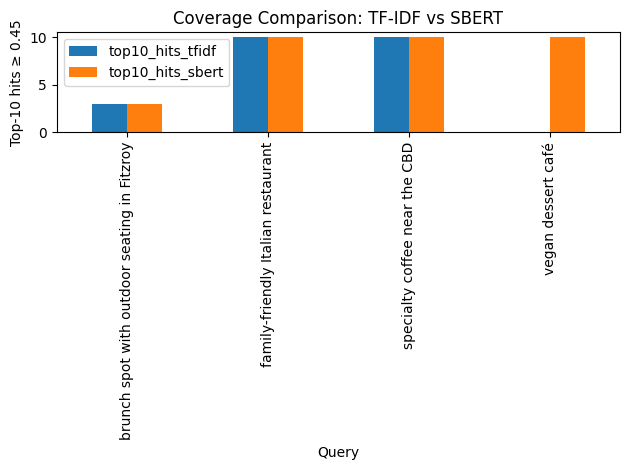

In [10]:
# Visual Comparison

import matplotlib.pyplot as plt

if sb is not None:
    ax = cmp.set_index("query")[["top10_hits_tfidf","top10_hits_sbert"]].plot(kind="bar")
    ax.set_ylabel("Top-10 hits ≥ 0.45")
    ax.set_xlabel("Query")
    ax.set_title("Coverage Comparison: TF-IDF vs SBERT")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "compare_top10_hits.png", dpi=150)
    plt.show()

**# Interpretation — TF-IDF vs SBERT Retrieval Coverage**

This bar chart compares how many top-10 results (per query) achieved a cosine similarity of 0.45 or higher for the TF-IDF and SBERT search methods.

**Observations:**

Family-friendly Italian restaurant and specialty coffee near the CBD reached a full 10/10 match rate under both methods, indicating that both lexical (TF-IDF) and semantic (SBERT) signals aligned well for clearly described venues.

Brunch spot with outdoor seating in Fitzroy produced fewer confident hits because those phrases appear sparsely or with wording variations (e.g., “breakfast café,” “open-air”). TF-IDF is literal, so it misses near-synonyms; SBERT partially recovers them through meaning similarity.

Vegan dessert café was captured only by SBERT, showing its advantage in connecting related ideas (e.g., “plant-based sweets,” “dairy-free patisserie”) that don’t share exact tokens.

**Interpretation:**
TF-IDF performs well when the query wording overlaps directly with venue text, while SBERT captures deeper semantic relationships. In practical use, combining both could balance precision (literal match) and recall (conceptual similarity).

### Insights

**Two retrieval styles:**  
- **TF‑IDF + FAISS** matches exact or near‑exact words.  
- **SBERT MiniLM + FAISS** matches meaning, even with different wording.

**Similarity scores (cosine):**  
Think of each text as an arrow in space. If a venue and a query point in the same direction, the score is high.  
Approximate guide: **0.70+ strong**, **0.45–0.70 usable**, **<0.45 weak**.

**Observed patterns:**  
- SBERT returns more usable matches because it recognises paraphrases (e.g., “brunch café” ≈ “breakfast spot”).  
- TF‑IDF prioritises exact tokens (e.g., a specific suburb), making it very transparent but less flexible.  
- Descriptive queries (e.g., “family‑friendly Italian restaurant”, “vegan dessert café”) benefit from SBERT’s semantic understanding.

**Why results can be imperfect:** short OSM texts, richer inner‑city descriptions (urban bias), and English‑centric wording.


In [11]:
#Records versions and creates a ZIP of all outputs for submission.


import platform, json, shutil, os

env = {
    "python": platform.python_version(),
    "platform": platform.platform(),
}
try:
    import faiss
    env["faiss"] = faiss.__version__
except Exception:
    env["faiss"] = "unknown"
try:
    import sentence_transformers
    env["sentence_transformers"] = sentence_transformers.__version__
except Exception:
    env["sentence_transformers"] = "not_used"

with open(OUT_DIR/"environment.json","w") as f: json.dump(env, f, indent=2)

zip_path = "/kaggle/working/Task3_Outputs.zip" if str(OUT_DIR).startswith("/kaggle/working") else "Task3_Outputs.zip"
if os.path.exists(zip_path): os.remove(zip_path)
shutil.make_archive(zip_path.replace(".zip",""), "zip", OUT_DIR)
print("Created:", zip_path)


Created: /kaggle/working/Task3_Outputs.zip


In [12]:
#Sanity Check

# Reload and check index sizes match the number of texts
try:
    import faiss
    idx_tfidf = faiss.read_index(str(OUT_DIR/"faiss_tfidf_ip.idx"))
    print("TF-IDF index size:", idx_tfidf.ntotal, "==", len(texts))
except Exception as e:
    print("TF-IDF index check skipped:", e)

try:
    idx_sbert = faiss.read_index(str(OUT_DIR/"faiss_sbert_ip.idx"))
    print("SBERT index size:", idx_sbert.ntotal, "==", len(texts))
except Exception as e:
    print("SBERT index check skipped:", e)


TF-IDF index size: 1896 == 1896
SBERT index size: 1896 == 1896


In [13]:
!rm -f Task3_Outputs.zip && zip -r -q Task3_Outputs.zip Task3_Outputs

from IPython.display import FileLink, display
display(FileLink("Task3_Outputs.zip"))

/kaggle/working/Task3_Outputs.zip